# Week 3 – The Cleaning Sprint
**Project:** Moneyball – IPL Player Valuation  
**Course:** 24ADI204 – Data Science and Visualization

This notebook follows the Week 3 activity in the DSV Rule Book: handling missing values using suitable strategies and detecting outliers using boxplots, IQR and Z-score.

**Important:** The raw dataset is preserved in `original_df`. Cleaning is performed on `cleaned_df`. Missing statistics that are undefined or unavailable are not replaced with invented values. Valid extreme IPL performances are reviewed and retained unless there is evidence of an error.


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [17]:
df = pd.read_csv("IPL_Moneyball_Merged_2008_2026.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (3311, 27)


,season,player,runs,balls_faced,innings,fours,sixes,dismissals,balls_bowled,runs_conceded,...,acquisition_type,base_price_lakh,final_price_lakh,bat_style,bowl_style,player_full_name,strike_rate,batting_avg,economy,bowling_avg
0,2008,A Chopra,42,52,5,5,0,5,0,0,...,NaN,NaN,NaN,Right hand Bat,"Right arm Medium, Right arm Offbreak",Aakash Chopra,80.77,8.40,NaN,NaN
1,2008,A Kumble,13,17,4,1,0,2,230,304,...,auction,NaN,125.0,Right hand Bat,Legbreak Googly,Anil Kumble,76.47,6.50,7.93,43.43
2,2008,A Mishra,37,42,3,3,0,3,119,138,...,NaN,NaN,NaN,Right hand Bat,Legbreak,Amit Mishra,88.10,12.33,6.96,12.55
3,2008,A Mukund,0,1,1,0,0,1,0,0,...,NaN,NaN,NaN,Left hand Bat,Legbreak Googly,Abhinav Mukund,0.00,0.00,NaN,NaN
4,2008,A Nehra,3,13,3,0,0,1,269,348,...,auction,NaN,100.0,Right hand Bat,Left arm Medium fast,Ashish Nehra,23.08,3.00,7.76,29.00


In [19]:
original_df = df.copy()

print("Original dataset preserved successfully!")
print("Original Shape:", original_df.shape)

Original dataset preserved successfully!
Original Shape: (3311, 27)


In [20]:
print("First 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

First 5 Records:


,season,player,runs,balls_faced,innings,fours,sixes,dismissals,balls_bowled,runs_conceded,...,acquisition_type,base_price_lakh,final_price_lakh,bat_style,bowl_style,player_full_name,strike_rate,batting_avg,economy,bowling_avg
0,2008,A Chopra,42,52,5,5,0,5,0,0,...,NaN,NaN,NaN,Right hand Bat,"Right arm Medium, Right arm Offbreak",Aakash Chopra,80.77,8.40,NaN,NaN
1,2008,A Kumble,13,17,4,1,0,2,230,304,...,auction,NaN,125.0,Right hand Bat,Legbreak Googly,Anil Kumble,76.47,6.50,7.93,43.43
2,2008,A Mishra,37,42,3,3,0,3,119,138,...,NaN,NaN,NaN,Right hand Bat,Legbreak,Amit Mishra,88.10,12.33,6.96,12.55
3,2008,A Mukund,0,1,1,0,0,1,0,0,...,NaN,NaN,NaN,Left hand Bat,Legbreak Googly,Abhinav Mukund,0.00,0.00,NaN,NaN
4,2008,A Nehra,3,13,3,0,0,1,269,348,...,auction,NaN,100.0,Right hand Bat,Left arm Medium fast,Ashish Nehra,23.08,3.00,7.76,29.00



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3311 entries, 0 to 3310
Data columns (total 27 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   season            3311 non-null   int64  
 1   player            3311 non-null   object 
 2   runs              3311 non-null   int64  
 3   balls_faced       3311 non-null   int64  
 4   innings           3311 non-null   int64  
 5   fours             3311 non-null   int64  
 6   sixes             3311 non-null   int64  
 7   dismissals        3311 non-null   int64  
 8   balls_bowled      3311 non-null   int64  
 9   runs_conceded     3311 non-null   int64  
 10  wickets           3311 non-null   int64  
 11  matches_bowled    3311 non-null   int64  
 12  auction_name      2111 non-null   object 
 13  team              2111 non-null   object 
 14  role              893 non-null    object 
 15  nationality       1015 non-null   object 
 16  status            21

,season,runs,balls_faced,innings,fours,sixes,dismissals,balls_bowled,runs_conceded,wickets,matches_bowled,base_price_lakh,final_price_lakh,strike_rate,batting_avg,economy,bowling_avg
count,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,202.000000,1831.000000,2928.000000,2634.000000,2181.000000,1791.000000
mean,2017.180308,111.740260,84.116581,5.526729,10.100272,4.568710,4.320749,83.756267,115.550891,3.960435,4.330414,74.497525,366.022529,111.163941,19.903561,9.086479,36.033266
std,5.591679,152.618255,108.881763,4.950675,14.948681,7.232691,4.362480,105.775668,140.333831,5.706408,4.974391,57.238340,408.049119,49.905554,15.220876,2.643117,23.196671
min,2008.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,9.000000,0.000000,0.000000,0.000000,0.000000
25%,2012.000000,4.000000,5.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,25.000000,68.750000,85.710000,8.000000,7.530000,22.410000
50%,2017.000000,34.000000,30.000000,4.000000,3.000000,1.000000,3.000000,30.000000,51.000000,1.000000,2.000000,50.000000,200.000000,117.500000,18.000000,8.580000,29.570000
75%,2022.000000,179.000000,132.000000,9.000000,15.000000,6.000000,7.000000,138.000000,194.000000,6.000000,7.500000,100.000000,500.000000,140.000000,29.000000,10.000000,41.000000
max,2026.000000,973.000000,640.000000,19.000000,88.000000,59.000000,18.000000,420.000000,566.000000,32.000000,19.000000,200.000000,2520.000000,400.000000,152.000000,36.000000,248.000000



Number of Rows: 3311
Number of Columns: 27


In [21]:
missing_data = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100,
    'Data_Type': df.dtypes
})

missing_data = missing_data[
    missing_data['Missing_Count'] > 0
].sort_values(by='Missing_Count', ascending=False)

print(missing_data.to_string())

print("\nTotal Missing Values:", df.isnull().sum().sum())

                  Missing_Count  Missing_Percentage Data_Type
base_price_lakh            3109           93.899124   float64
role                       2418           73.029296    object
nationality                2296           69.344609    object
bowling_avg                1520           45.907581   float64
final_price_lakh           1480           44.699487   float64
status                     1200           36.242827    object
team                       1200           36.242827    object
auction_name               1200           36.242827    object
acquisition_type           1200           36.242827    object
economy                    1130           34.128662   float64
batting_avg                 677           20.446995   float64
strike_rate                 383           11.567502   float64
bowl_style                   26            0.785261    object

Total Missing Values: 17839


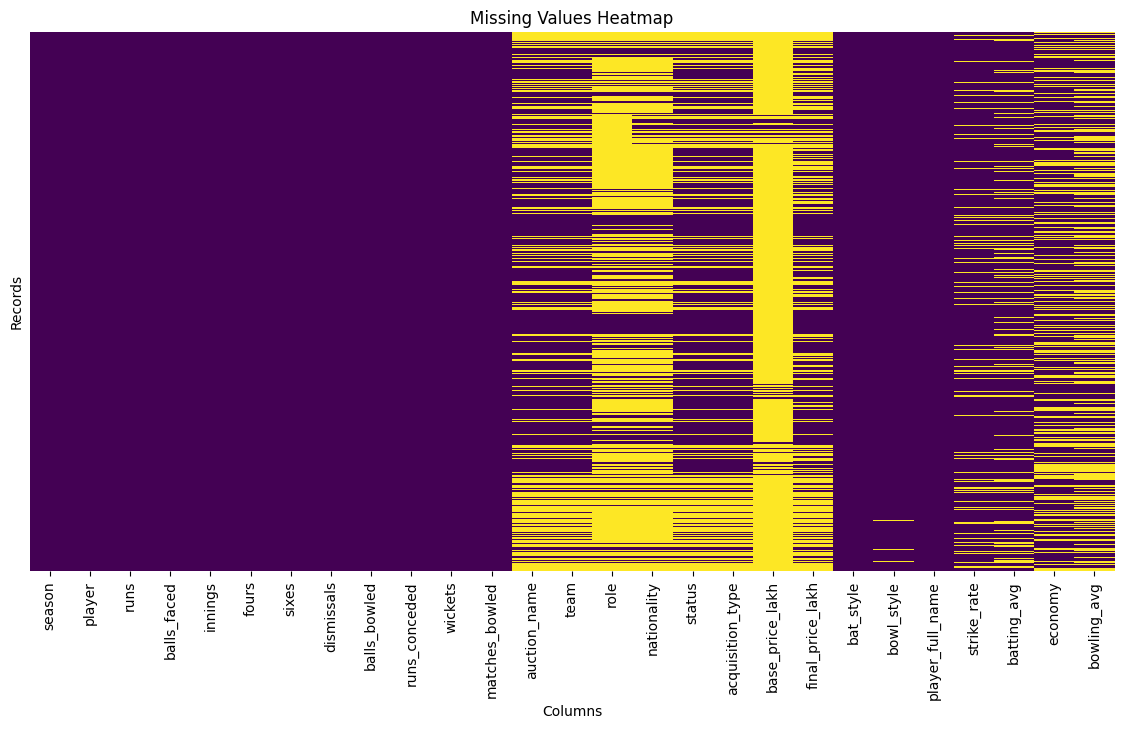

In [22]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values Heatmap")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.show()

In [23]:
auction_columns = [
    'base_price_lakh',
    'final_price_lakh',
    'status',
    'team',
    'auction_name',
    'acquisition_type'
]

print("Missing Auction Values:")
print(df[auction_columns].isnull().sum())

missing_auction = df[auction_columns].isnull().all(axis=1)

print("\nRows with all auction details missing:",
      missing_auction.sum())

display(
    df.loc[
        missing_auction,
        ['season', 'player'] + auction_columns
    ].head(10)
)

Missing Auction Values:
base_price_lakh     3109
final_price_lakh    1480
status              1200
team                1200
auction_name        1200
acquisition_type    1200
dtype: int64

Rows with all auction details missing: 1200


,season,player,base_price_lakh,final_price_lakh,status,team,auction_name,acquisition_type
0,2008,A Chopra,NaN,NaN,NaN,NaN,NaN,NaN
2,2008,A Mishra,NaN,NaN,NaN,NaN,NaN,NaN
3,2008,A Mukund,NaN,NaN,NaN,NaN,NaN,NaN
5,2008,A Nel,NaN,NaN,NaN,NaN,NaN,NaN
7,2008,AA Noffke,NaN,NaN,NaN,NaN,NaN,NaN
9,2008,AB Dinda,NaN,NaN,NaN,NaN,NaN,NaN
12,2008,AD Mascarenhas,NaN,NaN,NaN,NaN,NaN,NaN
13,2008,AM Nayar,NaN,NaN,NaN,NaN,NaN,NaN
14,2008,AM Rahane,NaN,NaN,NaN,NaN,NaN,NaN
15,2008,AS Yadav,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
other_columns = [
    col for col in df.columns
    if col not in auction_columns
]

other_missing = pd.DataFrame({
    'Missing_Count': df[other_columns].isnull().sum(),
    'Missing_Percentage': (
        df[other_columns].isnull().sum() / len(df)
    ) * 100
})

other_missing = other_missing[
    other_missing['Missing_Count'] > 0
].sort_values(by='Missing_Count', ascending=False)

print(other_missing.to_string())

             Missing_Count  Missing_Percentage
role                  2418           73.029296
nationality           2296           69.344609
bowling_avg           1520           45.907581
economy               1130           34.128662
batting_avg            677           20.446995
strike_rate            383           11.567502
bowl_style              26            0.785261


In [26]:
print("MISSING BATTING STATISTICS")

display(
    df[df['batting_avg'].isnull()][
        ['player', 'runs', 'innings',
         'balls_faced', 'batting_avg']
    ].head(10)
)

print("\nMISSING BOWLING STATISTICS")

display(
    df[df['bowling_avg'].isnull()][
        ['player', 'wickets', 'balls_bowled',
         'runs_conceded', 'bowling_avg', 'economy']
    ].head(10)
)

MISSING BATTING STATISTICS


,player,runs,innings,balls_faced,batting_avg
5,A Nel,0,0,0,NaN
16,Abdur Razzak,0,1,2,NaN
19,B Geeves,0,0,0,NaN
21,BAW Mendis,0,0,0,NaN
26,CRD Fernando,2,1,1,NaN
34,DL Vettori,0,0,0,NaN
36,DP Vijaykumar,1,1,1,NaN
39,DS Kulkarni,2,1,16,NaN
46,Gagandeep Singh,0,0,0,NaN
52,Iqbal Abdulla,1,1,2,NaN



MISSING BOWLING STATISTICS


,player,wickets,balls_bowled,runs_conceded,bowling_avg,economy
0,A Chopra,0,0,0,NaN,NaN
3,A Mukund,0,0,0,NaN,NaN
6,A Symonds,0,41,101,NaN,14.78
10,AB de Villiers,0,0,0,NaN,NaN
11,AC Gilchrist,0,0,0,NaN,NaN
14,AM Rahane,0,0,0,NaN,NaN
15,AS Yadav,0,0,0,NaN,NaN
16,Abdur Razzak,0,12,29,NaN,14.50
18,B Chipli,0,0,0,NaN,NaN
22,BB McCullum,0,0,0,NaN,NaN


In [27]:
print("Missing batting average with dismissals:")
print(
    df[
        df['batting_avg'].isnull() &
        (df['dismissals'] > 0)
    ].shape[0]
)

print("\nMissing strike rate with balls faced:")
print(
    df[
        df['strike_rate'].isnull() &
        (df['balls_faced'] > 0)
    ].shape[0]
)

print("\nMissing bowling average with wickets:")
print(
    df[
        df['bowling_avg'].isnull() &
        (df['wickets'] > 0)
    ].shape[0]
)

print("\nMissing economy with balls bowled:")
print(
    df[
        df['economy'].isnull() &
        (df['balls_bowled'] > 0)
    ].shape[0]
)

Missing batting average with dismissals:
0

Missing strike rate with balls faced:
0

Missing bowling average with wickets:
0

Missing economy with balls bowled:
0


In [28]:
cleaned_df = original_df.copy()

print("Working cleaned dataset created.")
print("Shape:", cleaned_df.shape)

Working cleaned dataset created.
Shape: (3311, 27)


### Missing-value treatment decision

The investigation showed that some missing batting and bowling statistics are mathematically undefined when a player has no relevant participation (for example, no dismissals or no wickets). Auction fields can also be unavailable for records without auction details.

For this sprint:
- `role`, `nationality`, and `bowl_style` are categorical profile fields. Missing values are labelled `Unknown`, not guessed.
- Auction fields and numerical performance statistics are retained as missing where the available evidence does not justify imputation.
- Numerical averages are **not** filled with zero or an overall mean/median, because that could create misleading player-performance values.

The choice preserves the meaning of the original data. The remaining missing values must be documented rather than described as errors that were all fixed.


In [29]:
categorical_columns = [
    'role',
    'nationality',
    'bowl_style'
]

for col in categorical_columns:
    cleaned_df[col] = cleaned_df[col].fillna('Unknown')

print("Categorical missing values handled.")

print(
    cleaned_df[categorical_columns].isnull().sum()
)

Categorical missing values handled.
role           0
nationality    0
bowl_style     0
dtype: int64


In [30]:
print("Duplicates before cleaning:",
      cleaned_df.duplicated().sum())

cleaned_df = cleaned_df.drop_duplicates()

print("Duplicates after cleaning:",
      cleaned_df.duplicated().sum())

Duplicates before cleaning: 0
Duplicates after cleaning: 0


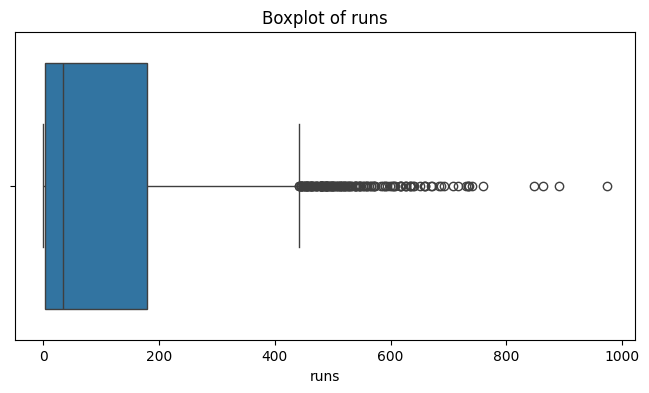

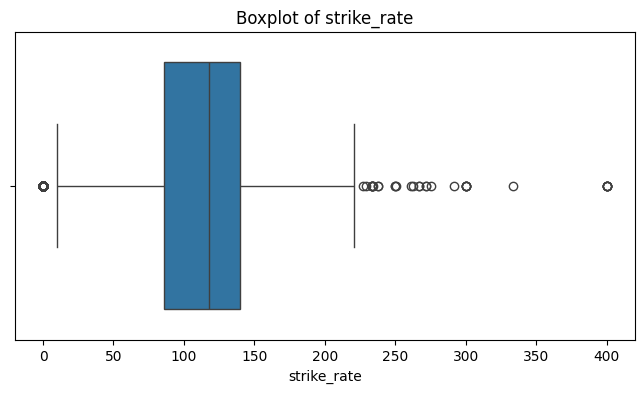

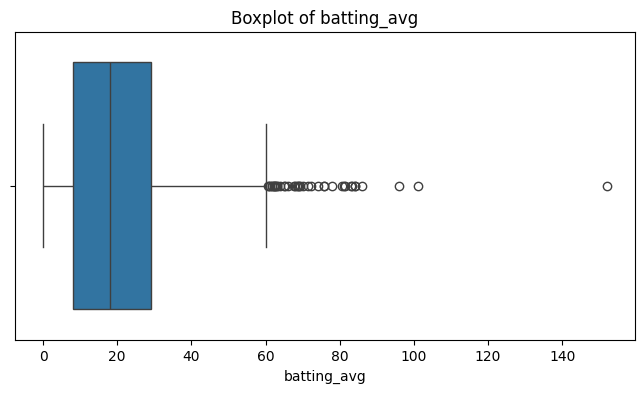

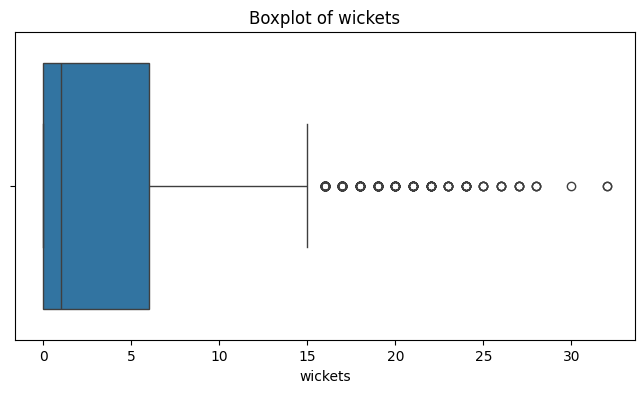

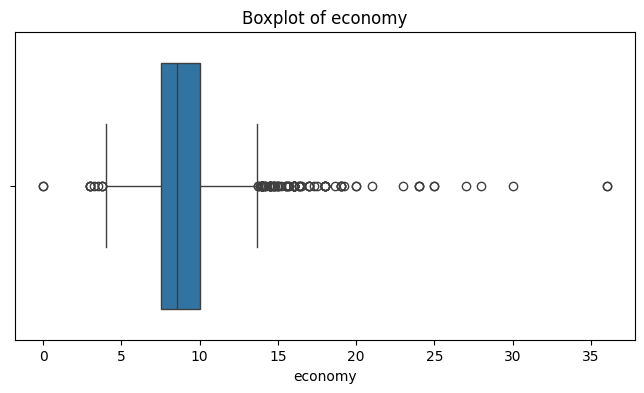

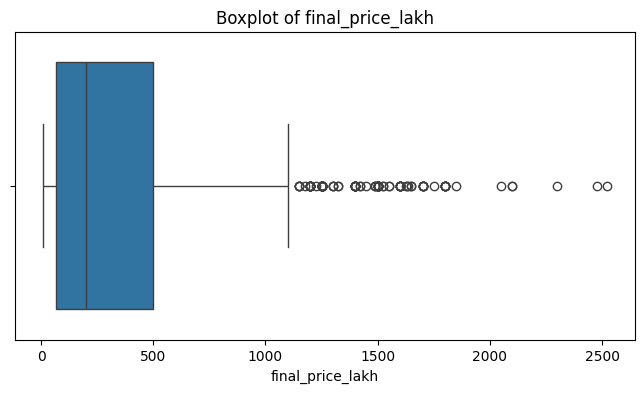

In [31]:
numeric_columns = [
    'runs',
    'strike_rate',
    'batting_avg',
    'wickets',
    'economy',
    'final_price_lakh'
]

for col in numeric_columns:
    plt.figure(figsize=(8, 4))

    sns.boxplot(x=cleaned_df[col])

    plt.title(f'Boxplot of {col}')
    plt.show()

In [32]:
iqr_results = {}

for col in numeric_columns:

    Q1 = cleaned_df[col].quantile(0.25)
    Q3 = cleaned_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = cleaned_df[
        (cleaned_df[col] < lower_limit) |
        (cleaned_df[col] > upper_limit)
    ]

    iqr_results[col] = len(outliers)

    print("\nColumn:", col)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Outliers:", len(outliers))


Column: runs
Lower Limit: -258.5
Upper Limit: 441.5
Outliers: 156

Column: strike_rate
Lower Limit: 4.2749999999999915
Upper Limit: 221.435
Outliers: 182

Column: batting_avg
Lower Limit: -23.5
Upper Limit: 60.5
Outliers: 39

Column: wickets
Lower Limit: -9.0
Upper Limit: 15.0
Outliers: 203

Column: economy
Lower Limit: 3.8250000000000006
Upper Limit: 13.705
Outliers: 107

Column: final_price_lakh
Lower Limit: -578.125
Upper Limit: 1146.875
Outliers: 130


In [33]:
from scipy.stats import zscore

zscore_results = {}

zscore_columns = [
    'runs',
    'strike_rate',
    'batting_avg',
    'wickets',
    'economy'
]

for col in zscore_columns:

    values = cleaned_df[col]

    z_scores = pd.Series(
        zscore(values, nan_policy='omit'),
        index=values.index
    )

    outlier_count = (z_scores.abs() > 3).sum()

    zscore_results[col] = outlier_count

    print(col, "Z-Score Outliers:", outlier_count)

runs Z-Score Outliers: 46
strike_rate Z-Score Outliers: 20
batting_avg Z-Score Outliers: 25
wickets Z-Score Outliers: 44
economy Z-Score Outliers: 31


In [34]:
outlier_comparison = pd.DataFrame({
    'IQR_Outliers': pd.Series(iqr_results),
    'ZScore_Outliers': pd.Series(zscore_results)
})

# Z-score was calculated for five performance columns only.
# final_price_lakh was assessed using IQR, not Z-score.
outlier_comparison['ZScore_Outliers'] = (
    outlier_comparison['ZScore_Outliers'].astype('object')
)
outlier_comparison.loc['final_price_lakh', 'ZScore_Outliers'] = 'Not calculated'

print(outlier_comparison)


### Interpretation of outlier results

IQR and Z-score identify unusual observations; they do not prove that a record is incorrect. IPL runs, strike rates, wickets, economy values and auction prices can contain legitimate extreme performances. The notebook therefore flags and reviews these observations but does not automatically delete or cap them.

`final_price_lakh` was checked with IQR only. Z-score was not calculated for that column, so the comparison displays **Not calculated** rather than a misleading `NaN`.


In [35]:
non_negative_columns = [
    'runs',
    'balls_faced',
    'innings',
    'fours',
    'sixes',
    'wickets',
    'balls_bowled',
    'runs_conceded',
    'final_price_lakh'
]

for col in non_negative_columns:

    invalid_count = (
        cleaned_df[col].dropna() < 0
    ).sum()

    print(col, "Negative Values:", invalid_count)

runs Negative Values: 0
balls_faced Negative Values: 0
innings Negative Values: 0
fours Negative Values: 0
sixes Negative Values: 0
wickets Negative Values: 0
balls_bowled Negative Values: 0
runs_conceded Negative Values: 0
final_price_lakh Negative Values: 0


## Before-and-after comparison

The cleaning operation in this notebook changes selected categorical missing values to `Unknown`. It does not change the number of rows or columns, does not remove duplicates (the original dataset contained none), and does not impute auction or numerical performance fields whose meaning is uncertain.

The expected comparison from the executed notebook is:
- Rows: 3,311 before and after
- Columns: 27 before and after
- Missing cells: 17,839 before; 13,099 after
- Missing cells handled: 4,740 (2,418 in `role`, 2,296 in `nationality`, and 26 in `bowl_style`)
- Duplicate rows: 0 before and after

This is a partial, meaning-preserving cleaning result—not a claim that every missing value has been eliminated.


In [36]:
comparison = pd.DataFrame({
    'Before Cleaning': [
        original_df.shape[0],
        original_df.shape[1],
        original_df.isnull().sum().sum(),
        original_df.duplicated().sum()
    ],

    'After Cleaning': [
        cleaned_df.shape[0],
        cleaned_df.shape[1],
        cleaned_df.isnull().sum().sum(),
        cleaned_df.duplicated().sum()
    ]
}, index=[
    'Rows',
    'Columns',
    'Missing Values',
    'Duplicate Rows'
])

print(comparison)

                Before Cleaning  After Cleaning
Rows                       3311            3311
Columns                      27              27
Missing Values            17839           13099
Duplicate Rows                0               0


In [37]:
missing_comparison = pd.DataFrame({
    'Before': original_df.isnull().sum(),
    'After': cleaned_df.isnull().sum()
})

missing_comparison['Values_Handled'] = (
    missing_comparison['Before'] -
    missing_comparison['After']
)

print(missing_comparison[
    missing_comparison['Before'] > 0
])

                  Before  After  Values_Handled
auction_name        1200   1200               0
team                1200   1200               0
role                2418      0            2418
nationality         2296      0            2296
status              1200   1200               0
acquisition_type    1200   1200               0
base_price_lakh     3109   3109               0
final_price_lakh    1480   1480               0
bowl_style            26      0              26
strike_rate          383    383               0
batting_avg          677    677               0
economy             1130   1130               0
bowling_avg         1520   1520               0


In [38]:
cleaned_df.to_csv(
    "IPL_Moneyball_Cleaned_Week03.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [39]:
print("FINAL CLEANED DATASET REPORT")

print("\nDataset Shape:", cleaned_df.shape)

print("Total Missing Values:",
      cleaned_df.isnull().sum().sum())

print("Duplicate Rows:",
      cleaned_df.duplicated().sum())

print("\nRemaining Missing Values:")
print(
    cleaned_df.isnull().sum()[
        cleaned_df.isnull().sum() > 0
    ]
)

print("\nFirst 5 Cleaned Records:")
display(cleaned_df.head())

FINAL CLEANED DATASET REPORT

Dataset Shape: (3311, 27)
Total Missing Values: 13099
Duplicate Rows: 0

Remaining Missing Values:
auction_name        1200
team                1200
status              1200
acquisition_type    1200
base_price_lakh     3109
final_price_lakh    1480
strike_rate          383
batting_avg          677
economy             1130
bowling_avg         1520
dtype: int64

First 5 Cleaned Records:


,season,player,runs,balls_faced,innings,fours,sixes,dismissals,balls_bowled,runs_conceded,...,acquisition_type,base_price_lakh,final_price_lakh,bat_style,bowl_style,player_full_name,strike_rate,batting_avg,economy,bowling_avg
0,2008,A Chopra,42,52,5,5,0,5,0,0,...,NaN,NaN,NaN,Right hand Bat,"Right arm Medium, Right arm Offbreak",Aakash Chopra,80.77,8.40,NaN,NaN
1,2008,A Kumble,13,17,4,1,0,2,230,304,...,auction,NaN,125.0,Right hand Bat,Legbreak Googly,Anil Kumble,76.47,6.50,7.93,43.43
2,2008,A Mishra,37,42,3,3,0,3,119,138,...,NaN,NaN,NaN,Right hand Bat,Legbreak,Amit Mishra,88.10,12.33,6.96,12.55
3,2008,A Mukund,0,1,1,0,0,1,0,0,...,NaN,NaN,NaN,Left hand Bat,Legbreak Googly,Abhinav Mukund,0.00,0.00,NaN,NaN
4,2008,A Nehra,3,13,3,0,0,1,269,348,...,auction,NaN,100.0,Right hand Bat,Left arm Medium fast,Ashish Nehra,23.08,3.00,7.76,29.00


## Week 3 conclusion

The notebook completed missing-value profiling, categorical treatment for three selected columns, duplicate checking, boxplot inspection, IQR detection and Z-score detection. The final dataset retains 13,099 missing cells because auction information and some performance statistics are unavailable or may be mathematically undefined. Six numerical columns were assessed with IQR; five performance columns were assessed with Z-score. Detected extreme values were retained pending evidence that they are data errors.

Use the saved cleaned dataset as the input for Week 4 EDA, while keeping the original raw dataset unchanged. In the Week 3 report, describe this as **targeted cleaning and outlier review**, not complete elimination of missing values or outliers.
